In [20]:
#Step 1: Import libraries
import os
os.environ["OMP_NUM_THREADS"]= "1"

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [21]:
#Step 2: Load the Kaggle dataset 
df=pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [22]:
#Step 3: Select input features
X=df[["Annual Income (k$)", "Spending Score (1-100)"]]

In [23]:
#Step 4: Find the optimal K using the Elbow Method
# WCSS stands for Within-Cluster Sum of Squares- It measures how far data points are from their assigned cluster centres.
wcss = []

for k in range(1,11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

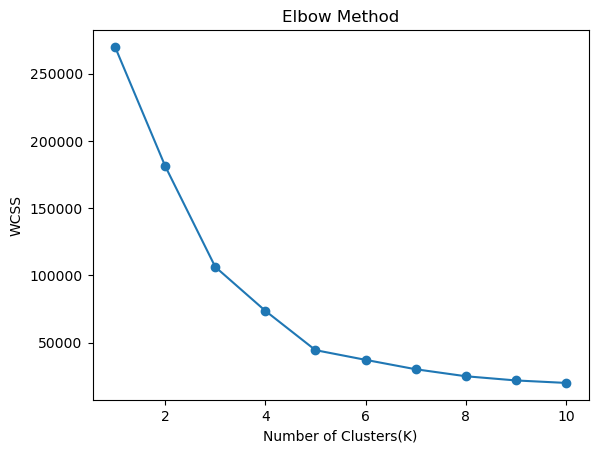

In [25]:
#Step 5: Pots the Elbow graph
plt.plot(range(1,11), wcss, marker="o")
plt.xlabel("Number of Clusters(K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [26]:
# Step 6: Apply K-Means using the selected K
model = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = model.fit_predict(X)

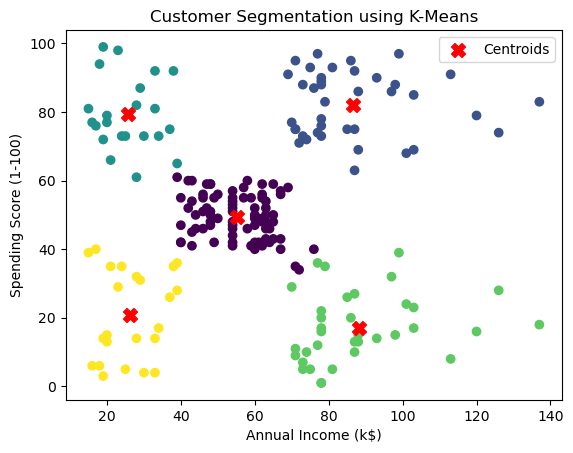

In [27]:
# Step 7: Visualize clusters and centroids
plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=df['Cluster']
)

# Plot the centroids
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=100,
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation using K-Means')
plt.legend()
plt.show()

In [28]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
...,...,...,...,...,...,...
195,196,Female,35,120,79,1
196,197,Female,45,126,28,3
197,198,Male,32,126,74,1
198,199,Male,32,137,18,3
